In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [22]:
# Load model and recreate test dataset

# Load cleaned dataset
df = pd.read_csv(
    "../data/processed/supply_chain_cleaned.csv",
    encoding="latin1"
)

# Remove cancelled orders
df_model = df[
    df["Delivery Status"] != "Shipping canceled"
].copy()

# Create target
df_model["Target"] = (
    df_model["Delivery Status"] == "Late delivery"
).astype(int)

# Selected features
selected_features = [
    "Shipping Mode",
    "Days for shipment (scheduled)",
    "Customer Segment",
    "Market",
    "Order Region",
    "Department Name",
    "Category Name",
    "Order Item Quantity",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Product Price"
]

X = df_model[selected_features].copy()
y = df_model["Target"].copy()
groups = df_model["Order Id"]

# Recreate the same group-based test split
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X, y, groups=groups)
)

X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

# Load trained model
final_group_model = joblib.load(
    "../models/best_model.pkl"
)

# Generate predictions
test_probabilities = final_group_model.predict_proba(X_test)[:, 1]

selected_threshold = 0.40

test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

print("Model loaded successfully!")
print("Test dataset shape:", X_test.shape)
print("Test predictions generated!")

Model loaded successfully!
Test dataset shape: (34272, 11)
Test predictions generated!


Confusion Matrix:
[[ 7062  7488]
 [ 4642 15080]]


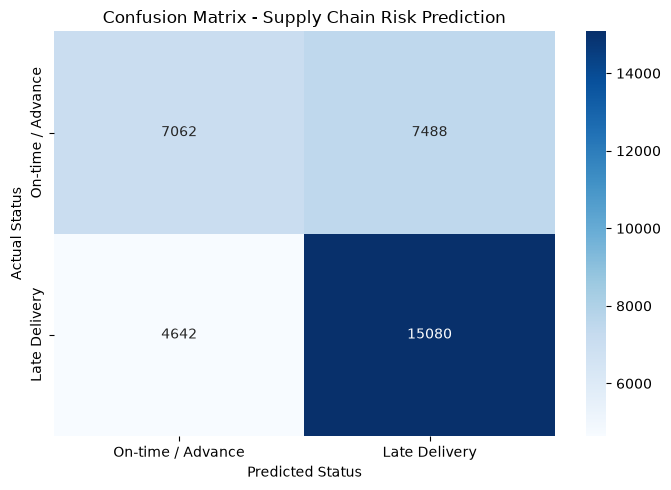

In [23]:
# confusion matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, test_predictions)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["On-time / Advance", "Late Delivery"],
    yticklabels=["On-time / Advance", "Late Delivery"]
)

plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.title("Confusion Matrix - Supply Chain Risk Prediction")

plt.tight_layout()

plt.savefig(
    "../reports/figures/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
# classification report

from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    test_predictions,
    target_names=["On-time / Advance", "Late Delivery"],
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))

,precision,recall,f1-score,support
On-time / Advance,0.6034,0.4854,0.5380,14550.0000
Late Delivery,0.6682,0.7646,0.7132,19722.0000
accuracy,0.6461,0.6461,0.6461,0.6461
macro avg,0.6358,0.6250,0.6256,34272.0000
weighted avg,0.6407,0.6461,0.6388,34272.0000


In [25]:
# Individual evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions),
    "Recall": recall_score(y_test, test_predictions),
    "F1 Score": f1_score(y_test, test_predictions),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities)
}

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Score"]
)

display(metrics_df.round(4))

,Metric,Score
0,Accuracy,0.6461
1,Precision,0.6682
2,Recall,0.7646
3,F1 Score,0.7132
4,ROC-AUC,0.7392


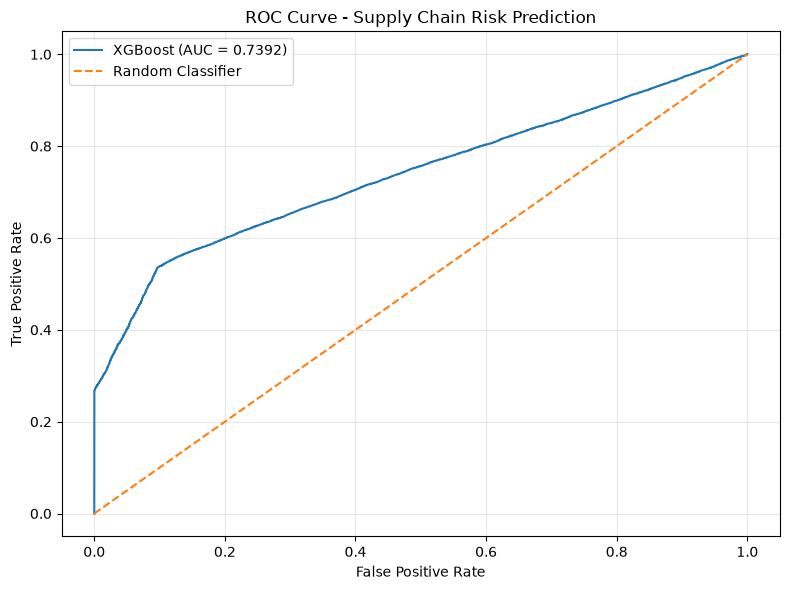

ROC-AUC Score: 0.7392


In [26]:
# ROC Curve generate

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(
    y_test,
    test_probabilities
)

# Calculate AUC
roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost (AUC = {roc_auc:.4f})"
)

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Supply Chain Risk Prediction")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))

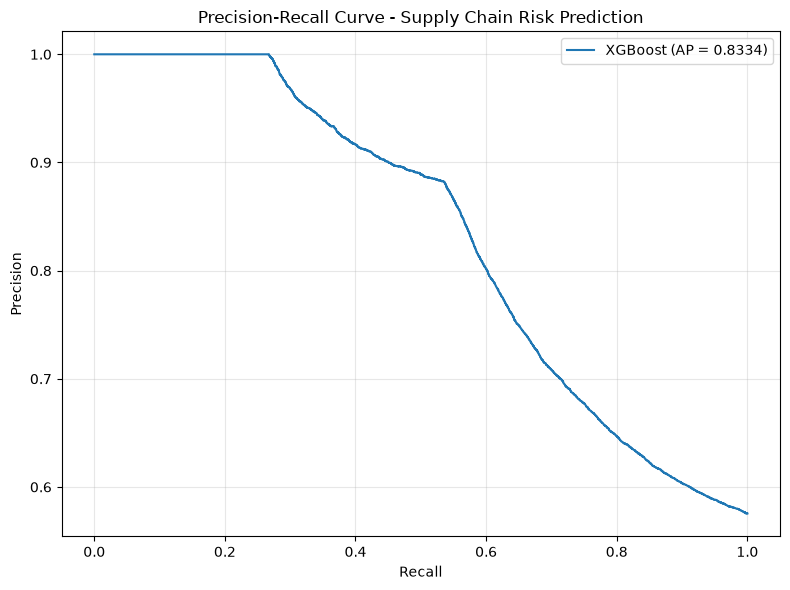

Average Precision Score: 0.8334


In [27]:
# Precision-Recall Curve

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

# Calculate precision and recall
precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(y_test, test_probabilities)
)

# Calculate Average Precision
avg_precision = average_precision_score(
    y_test,
    test_probabilities
)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"XGBoost (AP = {avg_precision:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Supply Chain Risk Prediction")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Average Precision Score:", round(avg_precision, 4))

In [28]:
# Comparison Threshold

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

thresholds_to_test = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds_to_test:

    predictions = (
        test_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions
    ).ravel()

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(y_test, predictions)

    f1 = f1_score(y_test, predictions)

    accuracy = accuracy_score(y_test, predictions)

    specificity = tn / (tn + fp)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "Specificity": specificity
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1_Score,Specificity
0,0.30,0.5763,0.5763,0.9961,0.7301,0.0073
1,0.35,0.5812,0.5808,0.9783,0.7289,0.0430
2,0.40,0.6461,0.6682,0.7646,0.7132,0.4854
3,0.45,0.6860,0.8154,0.5873,0.6828,0.8197
4,0.50,0.6920,0.8620,0.5534,0.6741,0.8799
5,0.55,0.6916,0.8776,0.5393,0.6681,0.8981
6,0.60,0.6919,0.8808,0.5373,0.6674,0.9014


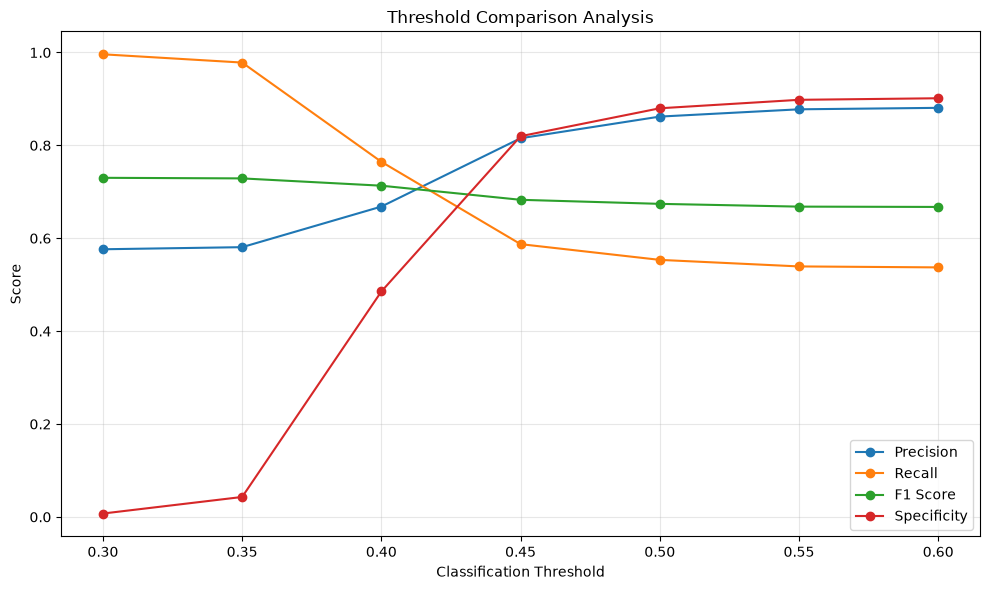

In [29]:
# Visualization

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1_Score"],
    marker="o",
    label="F1 Score"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Specificity"],
    marker="o",
    label="Specificity"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Comparison Analysis")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/threshold_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
# final evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

final_metrics = {
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, test_predictions),
        precision_score(y_test, test_predictions),
        recall_score(y_test, test_predictions),
        f1_score(y_test, test_predictions),
        roc_auc_score(y_test, test_probabilities)
    ]
}

final_metrics_df = pd.DataFrame(final_metrics)

final_metrics_df["Score (%)"] = (
    final_metrics_df["Score"] * 100
).round(2)

display(final_metrics_df)

,Metric,Score,Score (%)
0,Accuracy,0.646067,64.61
1,Precision,0.668203,66.82
2,Recall,0.764628,76.46
3,F1 Score,0.713171,71.32
4,ROC-AUC,0.739245,73.92


### 1. Model Limitations

1. **False Positive Predictions:** The model sometimes predicts on-time orders as high-risk orders, which may create unnecessary alerts.

2. **False Negative Predictions:** Some actual late deliveries are not identified by the model, which may affect supply chain planning.

3. **Historical Dataset:** The model is trained on historical DataCo supply chain records and may not represent current logistics conditions.

4. **Limited Features:** Important real-world factors such as weather conditions, traffic, warehouse delays, carrier performance and real-time shipment tracking are not included.

5. **Model Performance:** The model achieves a recall of approximately 76.46% and ROC-AUC of 73.92%, indicating useful predictive capability but leaving room for improvement.

6. **Prediction Threshold:** The selected threshold of 0.40 involves a trade-off between identifying more late deliveries and generating false alerts.

### 2. Business Recommendations

1. **Early Risk Identification:** Identify potentially delayed shipments so logistics teams can investigate them earlier.

2. **Shipping Mode Analysis:** Review the performance of different shipping modes, especially First Class shipments, which showed strong influence in the model's predictions.

3. **Delivery Planning:** Use scheduled shipping duration and historical delivery patterns to improve shipment planning.

4. **Operational Monitoring:** Monitor false alerts and missed late deliveries to improve the prediction system.

5. **Real-Time Data Integration:** Integrate live weather, traffic, warehouse and carrier information to improve future predictions.

6. **Continuous Model Improvement:** Retrain and evaluate the model periodically using recent and representative shipment data.

3. Business impact
Our system can help businesses:
- Identify potentially risky shipments.
- Prioritize shipments for operational review.
- Improve delivery planning.
- Reduce unexpected delivery delays through earlier intervention.
- Make data-driven logistics decisions.